# PNEUMYST AI · Preprocessing

8-bit gray → trim flat borders → pad to square → 320 px, plus per-image stats and transform parameters.

Outputs: `DATA_ROOT/processed/images_320/<dataset>/` and `DATA_ROOT/processed/manifests/<dataset>_processed.csv`.

Sections 2, 5d and 5e show real X-rays: strip their outputs before committing.

In [2]:
import json, shutil, sys, time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from dotenv import load_dotenv
load_dotenv(REPO / ".env")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import ml.eda.run_eda as eda
import ml.preprocessing.preprocess as pp
from ml.config import data_root

eda.SHOW = True
ROOT = data_root()
FIG = REPO / "docs" / "figures" / "preprocessing"
LOCAL = ROOT / "processed" / "preprocessing_qa"
FIG.mkdir(parents=True, exist_ok=True)
LOCAL.mkdir(parents=True, exist_ok=True)
PREV = {}
summary_path = FIG / "preprocess_summary.json"
if summary_path.exists():
    old = json.loads(summary_path.read_text())
    if old.get("version") != pp.VERSION:
        shutil.copy(summary_path, FIG / f"preprocess_summary_{old.get('version')}.json")
archived = sorted(FIG.glob("preprocess_summary_v*.json"))
if archived:
    PREV = json.loads(archived[-1].read_text())
print("DATA_ROOT:", ROOT, "| version:", pp.VERSION, "| comparing against:", PREV.get("version", "none"))

DATA_ROOT: C:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-data | version: v2 | comparing against: v1


## 1. Settings

In [ ]:
free_gb = shutil.disk_usage(ROOT).free / 1e9
{"version": pp.VERSION, **pp.asdict(pp.CONFIG), "free_disk_gb": round(free_gb, 1)}

{'version': 'v2',
 'size': 320,
 'flat_std': 4.0,
 'min_content': 0.5,
 'min_trim': 0.02,
 'intermediate': 512,
 'pad_value': 0,
 'free_disk_gb': 45.1}

## 2. One image, step by step (local only)

One image per dataset: gray → trimmed → padded → resized.

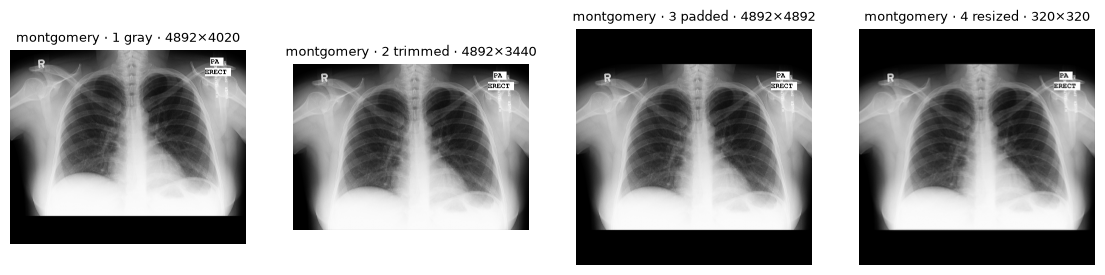

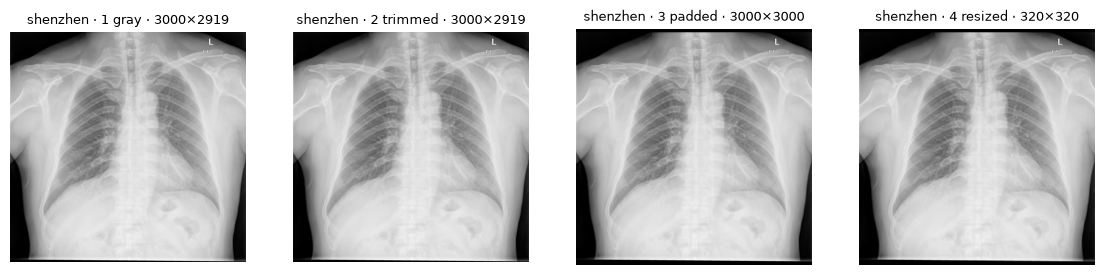

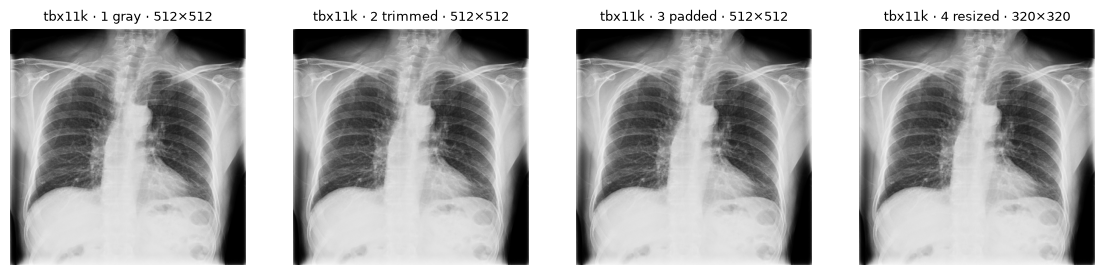

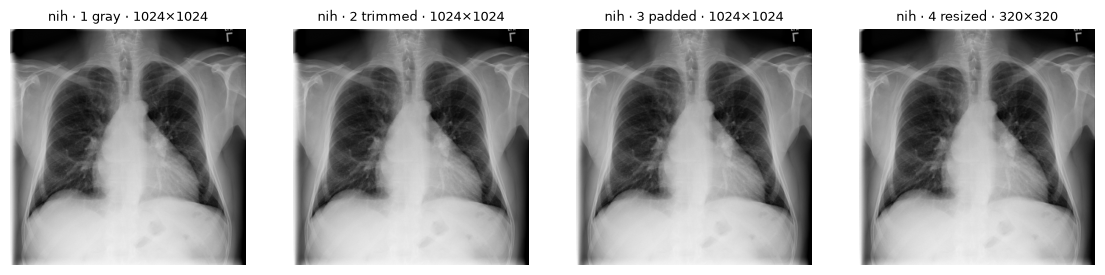

,dataset,file,raw_mode,raw_w×h,trimmed_w×h,square_side,final_w×h
0,montgomery,MCUCXR_0001_0.png,L,"(4892, 4020)","(4892, 3440)",4892,"(320, 320)"
1,shenzhen,CHNCXR_0001_0.png,P,"(3000, 2919)","(3000, 2919)",3000,"(320, 320)"
2,tbx11k,tb0005.png,RGB,"(512, 512)","(512, 512)",512,"(320, 320)"
3,nih,00000001_000.png,L,"(1024, 1024)","(1024, 1024)",1024,"(320, 320)"


In [ ]:
steps = []
for src in ["montgomery", "shenzhen", "tbx11k", "nih"]:
    r = pp.load_manifest(ROOT, src).iloc[0]
    path = ROOT / r["raw_path"]
    with Image.open(path) as im:
        raw_mode, raw_size = im.mode, im.size
    gray = pp.load_gray(path)
    x0, y0, x1, y1 = pp.flat_trim_box(gray)
    trimmed = gray[y0:y1, x0:x1]
    out, t = pp.preprocess_array(gray)
    square = np.zeros((t["square_side"],) * 2, np.uint8)
    square[t["pad_top"]:t["pad_top"] + trimmed.shape[0], t["pad_left"]:t["pad_left"] + trimmed.shape[1]] = trimmed
    steps.append({"dataset": src, "file": Path(r["raw_path"]).name, "raw_mode": raw_mode, "raw_w×h": raw_size,
                  "trimmed_w×h": trimmed.shape[::-1], "square_side": t["square_side"], "final_w×h": out.shape[::-1]})
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
    for ax, img, title in zip(axes, [gray, trimmed, square, out], ["1 gray", "2 trimmed", "3 padded", "4 resized"]):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{src} · {title} · {img.shape[1]}×{img.shape[0]}", fontsize=9)
        ax.axis("off")
    plt.show()
pd.DataFrame(steps)

## 3. Dry run (≈20 images per dataset)

Writes real outputs; the full run below picks up from here.

In [ ]:
dry = {s: pp.run_source(ROOT, s, workers=1, limit=20) for s in pp.SOURCES}
pd.DataFrame({s: d["proc_status"].value_counts() for s, d in dry.items()}).fillna(0).astype(int)

preprocess nih: 100%|██████████| 18/18 [00:00<00:00, 29.91it/s]


,tbx11k,shenzhen,montgomery,nih
proc_status,,,,
ok,18,20,20,18


## 4. Full run

Resumable: if it stops, rerun this cell and it continues. If it hangs on Windows, set `WORKERS = 1`.

In [ ]:
WORKERS = 4
processed, minutes = {}, {}
for s in pp.SOURCES:
    t0 = time.time()
    processed[s] = pp.run_source(ROOT, s, workers=WORKERS)
    minutes[s] = round((time.time() - t0) / 60, 1)
boxes320 = pp.transform_bboxes(ROOT, processed["nih"])
summary = pp.summarize(processed)
pd.DataFrame({s: {"rows": d["rows"], "ok": d["ok"], "failed": len(d["failed"]), "trimmed": d["trimmed"],
                  "padded": d["padded"], "minutes": minutes[s]} for s, d in summary["datasets"].items()}).T

preprocess nih: 100%|██████████| 112093/112093 [25:22<00:00, 73.63it/s]


,rows,ok,failed,trimmed,padded,minutes
tbx11k,8248.0,8248.0,0.0,17.0,16.0,0.9
shenzhen,662.0,662.0,0.0,1.0,644.0,0.9
montgomery,138.0,138.0,0.0,92.0,138.0,0.4
nih,112093.0,112093.0,0.0,13235.0,13101.0,25.6


## 5. QA

### 5a. Counts and failures

In [ ]:
qa = {s: {"manifest_rows": len(pp.load_manifest(ROOT, s)), "processed_ok": int((d["proc_status"] == "ok").sum()),
          "not_ok": int((d["proc_status"] != "ok").sum())} for s, d in processed.items()}
display(pd.DataFrame(qa).T)
pd.concat([d.loc[d["proc_status"] != "ok", ["image_id", "proc_status", "proc_reason"]] for d in processed.values()])

,manifest_rows,processed_ok,not_ok
tbx11k,8248,8248,0
shenzhen,662,662,0
montgomery,138,138,0
nih,112093,112093,0


,image_id,proc_status,proc_reason


### 5b. Output format (sample of 500 files)

In [ ]:
ok_all = pd.concat([d[d["proc_status"] == "ok"] for d in processed.values()])
check = ok_all.sample(min(500, len(ok_all)), random_state=0)
fmt = []
for p in check["processed_path"]:
    with Image.open(ROOT / p) as im:
        fmt.append((im.size, im.mode))
fmt = pd.Series(fmt).value_counts()
qa["format_sample"] = {str(k): int(v) for k, v in fmt.items()}
fmt

((320, 320), L)    500
Name: count, dtype: int64

### 5c. Brightness and sharpness after preprocessing

`_prev` columns: the previous version. Goal for v2: `sharpness_vs_tbx11k` under ~1.5–2× and far fewer NIH trims / pads.

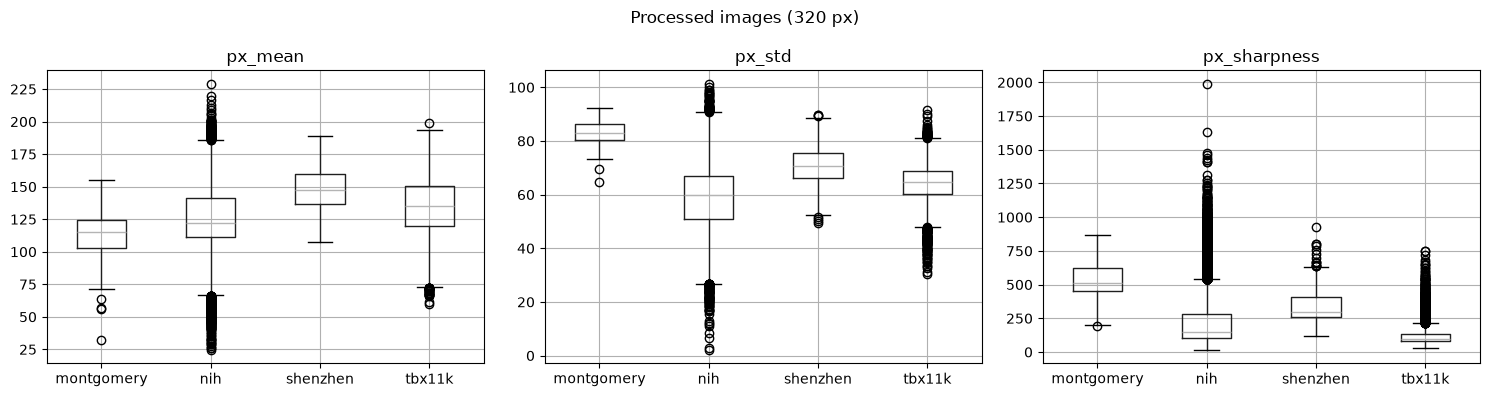

,px_mean,px_std,px_p1,px_p99,px_sharpness,px_black_frac,px_white_frac,trimmed,padded,sharpness_prev,trimmed_prev,padded_prev,sharpness_vs_tbx11k
source,,,,,,,,,,,,,
montgomery,114.89,82.79,0.0,251.0,514.64,0.19,0.03,92,138,536.912,137,138,5.20
nih,122.23,59.96,1.0,228.0,150.09,0.03,0.00,13235,13101,149.043,38072,25317,1.52
shenzhen,147.77,70.76,0.0,233.0,299.36,0.06,0.00,1,644,289.897,662,652,3.02
tbx11k,135.31,64.59,0.0,227.0,99.03,0.07,0.00,17,16,98.991,546,231,1.00


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["px_mean", "px_std", "px_sharpness"]):
    ok_all.boxplot(column=col, by="source", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Processed images (320 px)")
eda.save(fig, FIG / "01_processed_stats.png")
med = ok_all.groupby("source")[pp.STAT_COLS].median().round(2)
med["trimmed"] = pd.Series({s: d["trimmed"] for s, d in summary["datasets"].items()})
med["padded"] = pd.Series({s: d["padded"] for s, d in summary["datasets"].items()})
if PREV:
    med["sharpness_prev"] = pd.Series({s: d["stats_median"]["px_sharpness"] for s, d in PREV["datasets"].items()})
    med["trimmed_prev"] = pd.Series({s: d["trimmed"] for s, d in PREV["datasets"].items()})
    med["padded_prev"] = pd.Series({s: d["padded"] for s, d in PREV["datasets"].items()})
med["sharpness_vs_tbx11k"] = (med["px_sharpness"] / med.loc["tbx11k", "px_sharpness"]).round(2)
med

### 5d. Raw vs processed (local only)

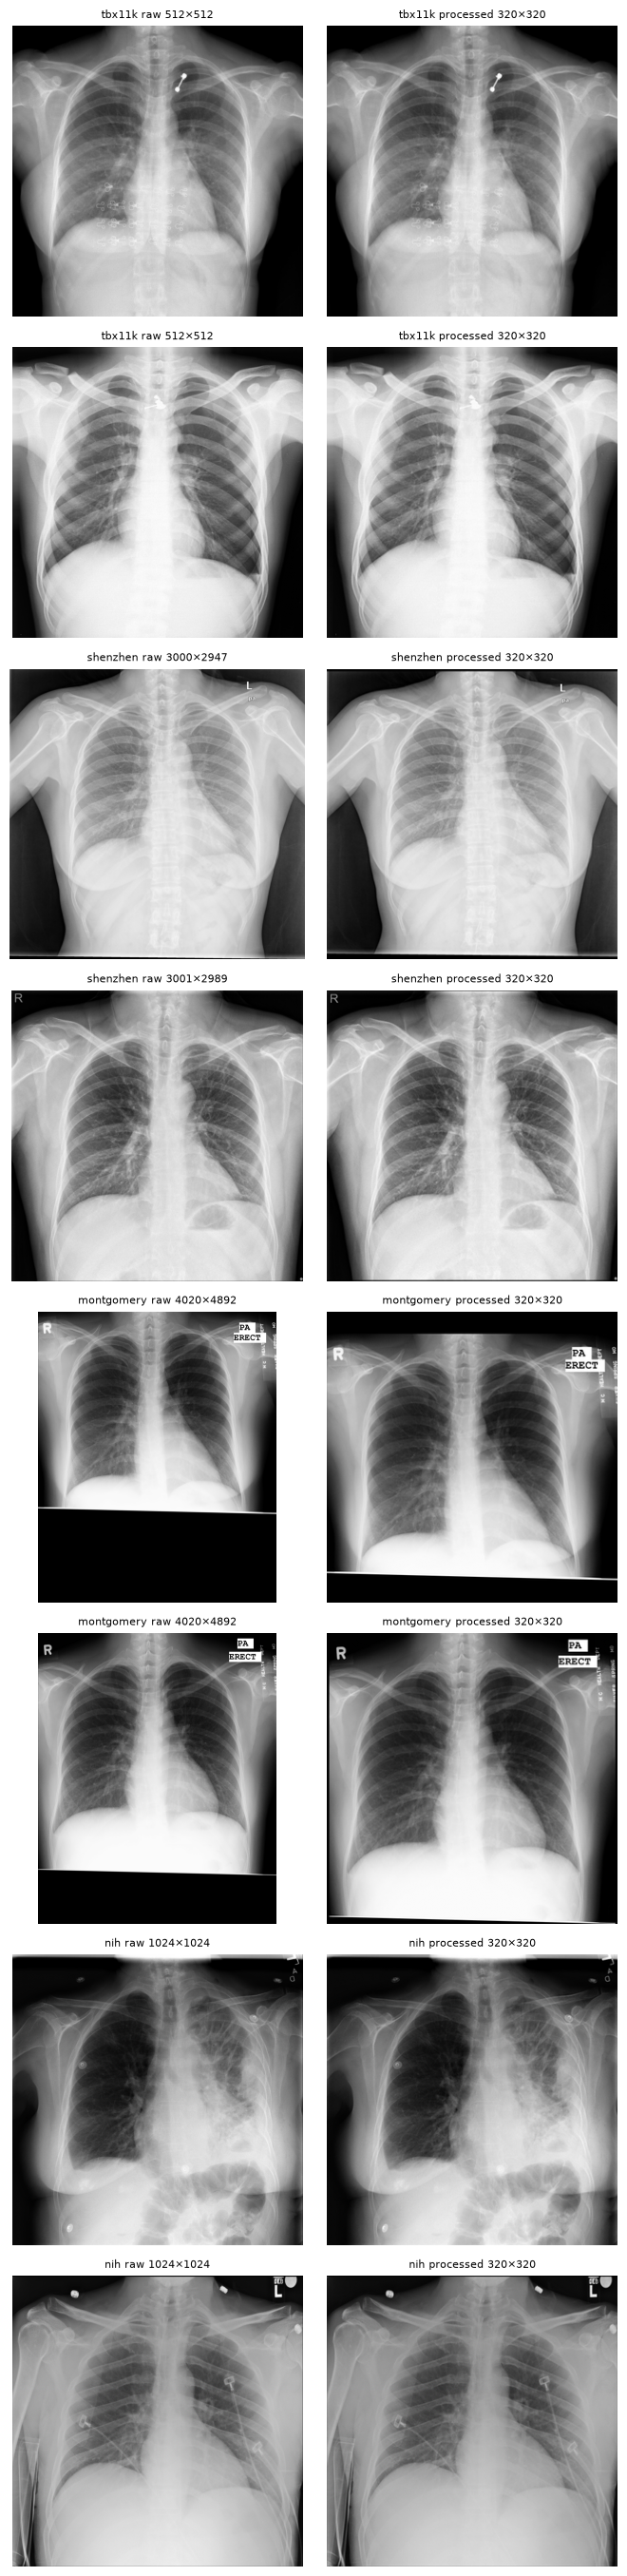

In [ ]:
pairs = []
for s, d in processed.items():
    for r in d[d["proc_status"] == "ok"].sample(2, random_state=1).itertuples():
        raw = pp.load_gray(ROOT / r.raw_path)
        with Image.open(ROOT / r.processed_path) as im:
            pairs.append((s, raw, np.asarray(im)))
fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3.4 * len(pairs)), squeeze=False)
for (s, raw, proc), (a, b) in zip(pairs, axes):
    a.imshow(raw, cmap="gray"); a.set_title(f"{s} raw {raw.shape[1]}×{raw.shape[0]}", fontsize=8); a.axis("off")
    b.imshow(proc, cmap="gray"); b.set_title(f"{s} processed {proc.shape[1]}×{proc.shape[0]}", fontsize=8); b.axis("off")
eda.save(fig, LOCAL / "raw_vs_processed.png")

### 5e. NIH boxes on processed images (local only)

The red box should sit on the same structure as in the original.

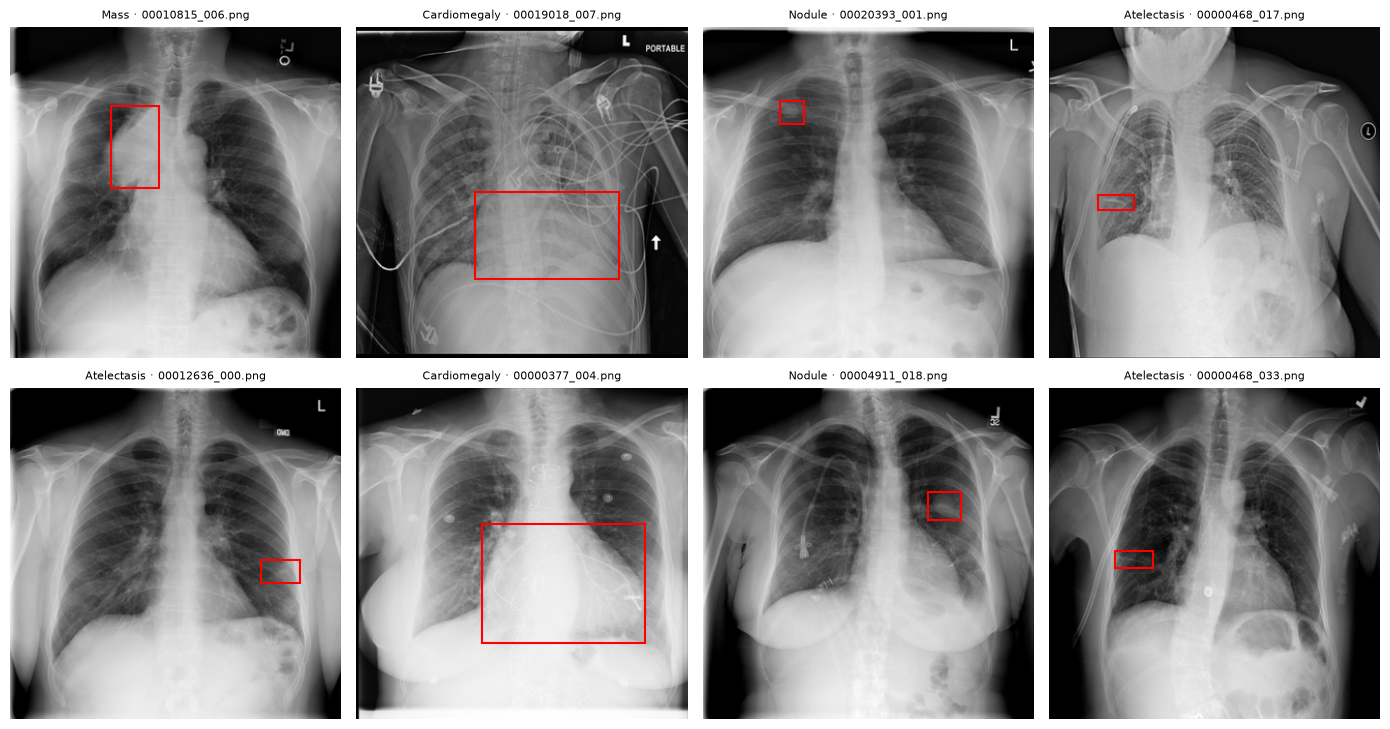

984

In [ ]:
pick = boxes320.drop_duplicates("image_id").sample(min(8, len(boxes320)), random_state=2)
paths = processed["nih"].set_index("image_id")["processed_path"]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, b in zip(axes.ravel(), pick.itertuples()):
    with Image.open(ROOT / paths[b.image_id]) as im:
        ax.imshow(np.asarray(im), cmap="gray")
    ax.add_patch(plt.Rectangle((b.x_320, b.y_320), b.w_320, b.h_320, fill=False, color="red", linewidth=1.5))
    ax.set_title(f"{b.finding} · {b.image_id.split(':')[1]}", fontsize=8)
eda.save(fig, LOCAL / "nih_boxes_320.png")
qa["nih_boxes_320"] = int(len(boxes320))
len(boxes320)

## 6. Shortcut probes at 320 px

Same probes as EDA sections 20–22, now on processed images. Lower = resizing narrowed the gap.

TBX11K classes: 100%|██████████| 2400/2400 [00:12<00:00, 186.18it/s]


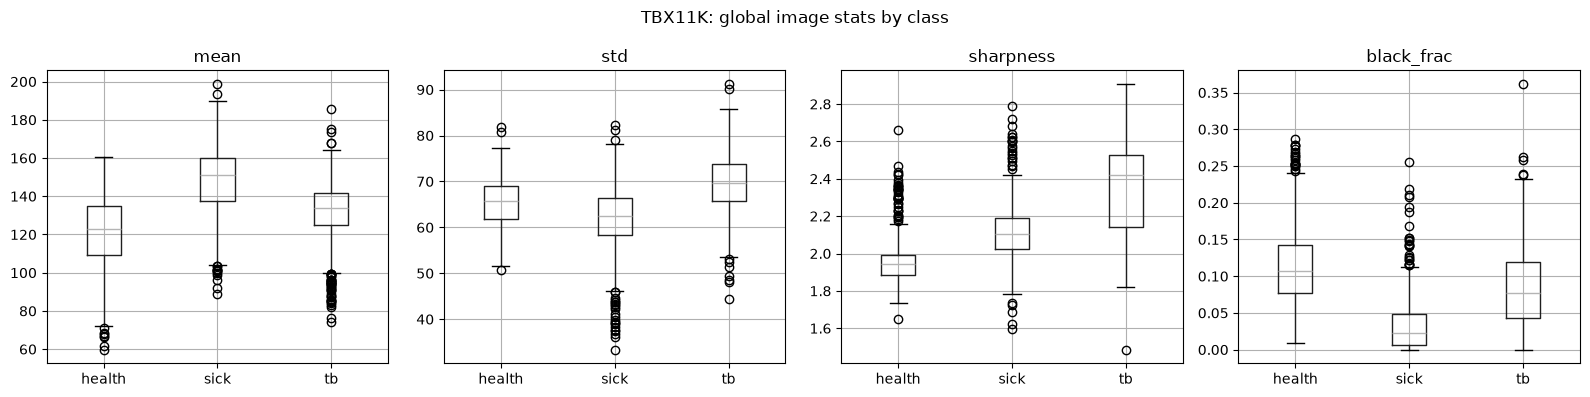

normals x 3 methods: 100%|██████████| 806/806 [00:09<00:00, 83.26it/s]


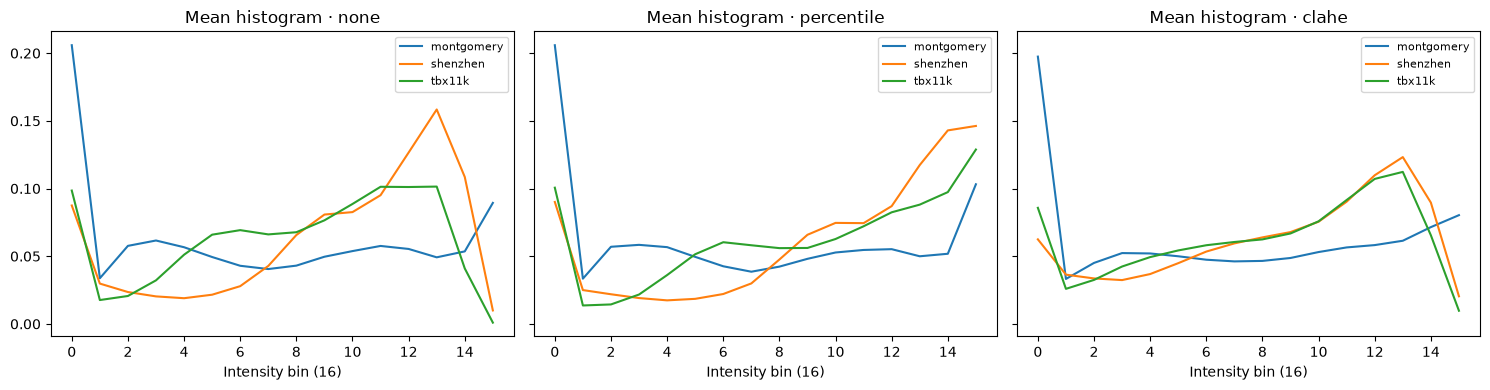

method,auroc_320px,auroc_raw (EDA),auroc_320px_v1
comparison,,,
health vs sick,0.985,0.985,0.986
health vs tb,0.978,0.976,0.972
sick vs tb,0.938,0.938,0.931
montgomery vs shenzhen,1.000,1.000,1.000
montgomery vs tbx11k,1.000,1.000,1.000
shenzhen vs tbx11k,0.994,0.994,0.991


In [ ]:
import ml.eda.probes as probes

proc_dfs = {s: d[d["proc_status"] == "ok"].assign(raw_path=lambda x: x["processed_path"]) for s, d in processed.items()}
_, tbx320 = probes.tbx_class_probe(proc_dfs["tbx11k"], ROOT, FIG, n_per_class=800)
origin320, _ = probes.origin_probe(proc_dfs, ROOT, FIG, n=400)

before = {}
eda_json = REPO / "docs" / "figures" / "eda" / "eda_probes_summary.json"
if eda_json.exists():
    e = json.loads(eda_json.read_text())
    before = {r["comparison"]: r["none"] for r in e["tbx11k_class_probe"] + e["origin_probe"]}
compare = pd.concat([tbx320[["none"]], origin320[["none"]]]).rename(columns={"none": "auroc_320px"})
compare["auroc_raw (EDA)"] = [before.get(c) for c in compare.index]
if PREV:
    prev_probe = {r["comparison"]: r["auroc_320px"] for r in PREV.get("probes_320", [])}
    compare[f"auroc_320px_{PREV['version']}"] = [prev_probe.get(c) for c in compare.index]
compare

## 7. Save summary

In [ ]:
out = {**summary, "qa": qa, "minutes": minutes, "probes_320": compare.reset_index().to_dict("records")}
(FIG / "preprocess_summary.json").write_text(json.dumps(out, indent=2, default=str))
print("saved", FIG / "preprocess_summary.json")

saved c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\docs\figures\preprocessing\preprocess_summary.json


## 8. NIH trimming check (after preprocessing)

Is border trimming linked to view, split or finding? If one group is trimmed far more often than the others,
the model could learn "padding = sick", so NIH would need stronger random-padding augmentation.


NIH images: 112,093 | trimmed: 13,235 (11.8%) | padded: 11.7%

Trimmed share by view:


,mean,sum,size
view,,,
AP,0.169,7578,44791
PA,0.084,5657,67302


Trimmed share by split:


,mean,sum,size
split,,,
test,0.129,3306,25588
train,0.114,8853,77335
val,0.117,1076,9170


Trimmed share by view x split:


split,test,train,val
view,,,
AP,0.169,0.169,0.169
PA,0.077,0.085,0.088


Trimmed share by finding (ratio > 1.5 or < 0.67 = worth a look):


,trimmed share,ratio_vs_overall
Hernia,0.088,0.75
Emphysema,0.104,0.88
Fibrosis,0.106,0.90
Mass,0.107,0.91
Atelectasis,0.110,0.93
Nodule,0.112,0.95
Effusion,0.114,0.97
Pneumothorax,0.117,0.99
No finding,0.117,0.99
Pleural thickening,0.126,1.07


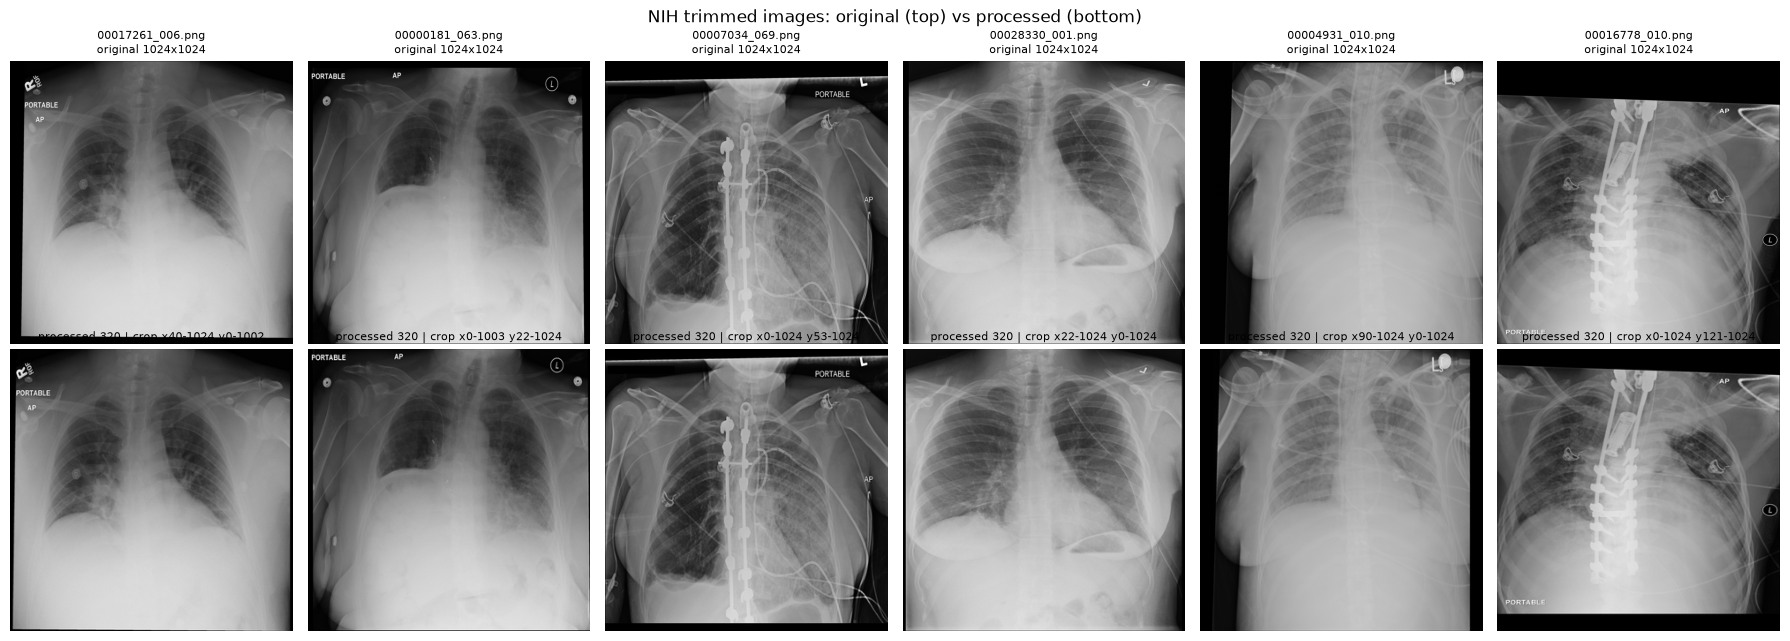

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from ml.config import data_root

ROOT = data_root()
p = pd.read_csv(ROOT / "processed" / "manifests" / "nih_processed.csv", low_memory=False)
p = p[p["proc_status"] == "ok"].copy()
p["trimmed"] = (p.crop_x1 - p.crop_x0) * (p.crop_y1 - p.crop_y0) < p.orig_w * p.orig_h
p["padded"] = (p.pad_left > 0) | (p.pad_top > 0)

overall = p["trimmed"].mean()
print(f"NIH images: {len(p):,} | trimmed: {p['trimmed'].sum():,} ({overall:.1%}) | padded: {p['padded'].mean():.1%}\n")

print("Trimmed share by view:")
display(p.groupby("view")["trimmed"].agg(["mean", "sum", "size"]).round(3))

print("Trimmed share by split:")
display(p.groupby("split")["trimmed"].agg(["mean", "sum", "size"]).round(3))

print("Trimmed share by view x split:")
display(p.pivot_table(index="view", columns="split", values="trimmed", aggfunc="mean").round(3))

from ml.datasets.targets import NIH_FINDINGS, label_column
label_cols = [label_column(f) for f in NIH_FINDINGS]
p["no_finding"] = p[label_cols].sum(axis=1) == 0
rows = {"No finding": p.loc[p["no_finding"], "trimmed"].mean()}
rows |= {c.replace("label_", "").replace("_", " ").capitalize(): p.loc[p[c] == 1, "trimmed"].mean() for c in label_cols}
by_finding = pd.Series(rows, name="trimmed share").sort_values()
by_finding = by_finding.to_frame().assign(ratio_vs_overall=lambda d: (d["trimmed share"] / overall).round(2))
print("Trimmed share by finding (ratio > 1.5 or < 0.67 = worth a look):")
display(by_finding.round(3))

# Visual check: original vs processed for 6 random trimmed images
sample = p[p["trimmed"]].sample(6, random_state=42)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for col, r in enumerate(sample.itertuples()):
    with Image.open(ROOT / r.raw_path) as im:
        orig = np.asarray(im.convert("L"))
    with Image.open(ROOT / r.processed_path) as im:
        proc = np.asarray(im)
    axes[0, col].imshow(orig, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{r.image_id.split(':')[1]}\noriginal {r.orig_w}x{r.orig_h}", fontsize=8)
    axes[1, col].imshow(proc, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"processed 320 | crop x{r.crop_x0}-{r.crop_x1} y{r.crop_y0}-{r.crop_y1}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("NIH trimmed images: original (top) vs processed (bottom)")
plt.tight_layout()
plt.show()